# TT-30 - ARIMA/SARIMA: Du bao luong khach hang theo thang
Du lieu: AirPassengers, 144 thang (1949-1960). Tu tai qua statsmodels, khong can
chuan bi file rieng (can mang khi chay lan dau de statsmodels tai du lieu).


## 1. Ve chuoi goc

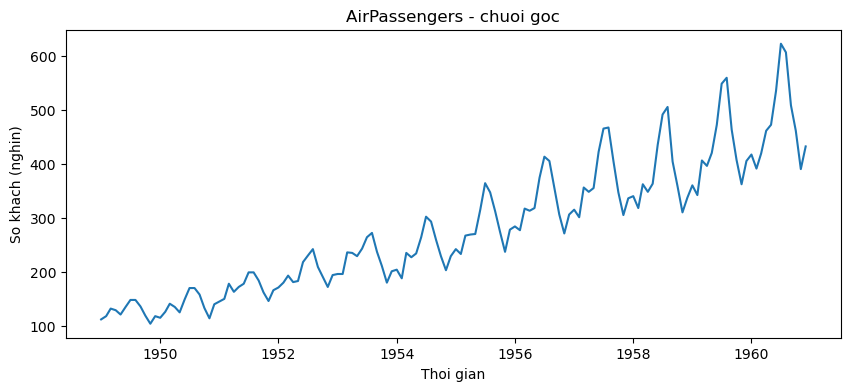

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

du_lieu = sm.datasets.get_rdataset("AirPassengers").data
du_lieu.columns = ["thang_thu_tu", "so_khach"]
y = pd.Series(du_lieu["so_khach"].values,
              index=pd.date_range("1949-01", periods=len(du_lieu), freq="MS"))

plt.figure(figsize=(10, 4))
plt.plot(y)
plt.title("AirPassengers - chuoi goc")
plt.xlabel("Thoi gian"); plt.ylabel("So khach (nghin)")
plt.show()
# Quan sat: trend tang ro ret, mua vu chu ky 12 thang, bien do dao dong PHINH DAN
# theo trend -> day la dau hieu mo hinh NHAN TINH, khong phai cong tinh


## 2. seasonal_decompose: multiplicative vs additive

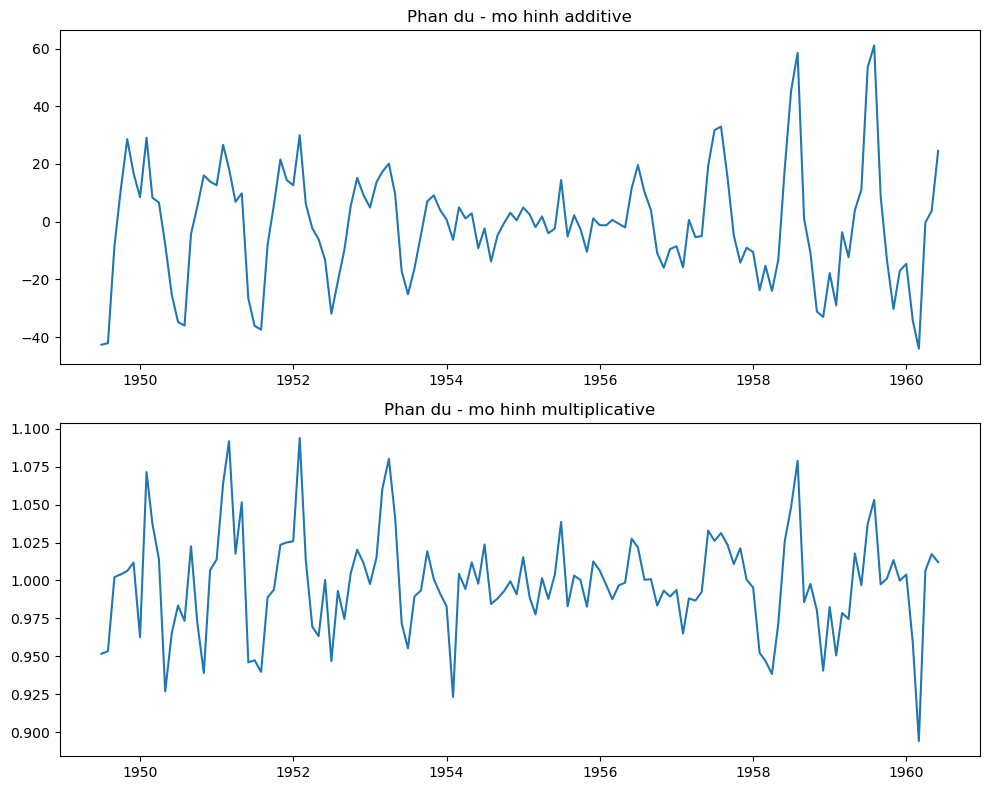

In [2]:
from statsmodels.tsa.seasonal import seasonal_decompose

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
for ax, mo_hinh in zip(axes, ["additive", "multiplicative"]):
    phan_ra = seasonal_decompose(y, model=mo_hinh, period=12)
    ax.plot(phan_ra.resid)
    ax.set_title(f"Phan du - mo hinh {mo_hinh}")
plt.tight_layout()
plt.show()
# Mo hinh multiplicative cho phan du PHANG hon (khong con phinh to theo thoi gian)
# -> xac nhan day la chuoi nhan tinh, hop voi quan sat o buoc 1


## 3. Lay log de bien thanh cong tinh

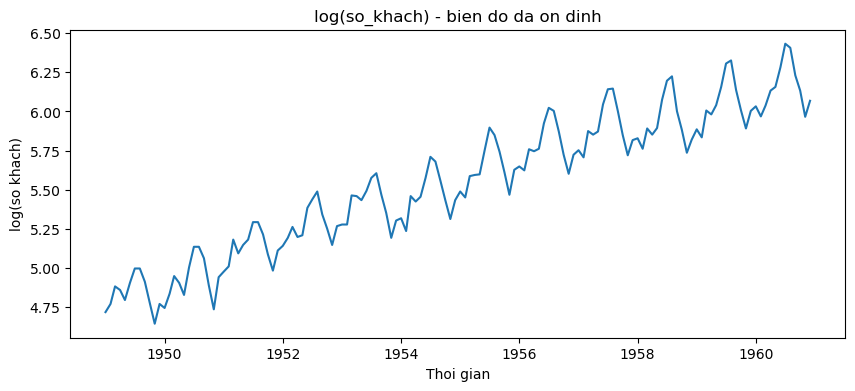

In [3]:
y_log = np.log(y)

plt.figure(figsize=(10, 4))
plt.plot(y_log)
plt.title("log(so_khach) - bien do da on dinh")
plt.xlabel("Thoi gian"); plt.ylabel("log(so khach)")
plt.show()
# Sau log, bien do dao dong mua vu gio DEU qua cac nam, khong con phinh to theo trend
# -> co the dung cac mo hinh cong tinh (ARIMA/SARIMA chuan) tren chuoi da log nay


## 4. ADF tren 4 phien ban chuoi -> xac dinh d, D

In [4]:
from statsmodels.tsa.stattools import adfuller

def kiem_dinh_adf(chuoi, ten):
    chuoi_sach = chuoi.dropna()
    stat, p, *_ = adfuller(chuoi_sach)
    return {"phien_ban": ten, "adf_stat": stat, "p_value": p,
            "ket_luan": "DUNG" if p < 0.05 else "KHONG DUNG"}

bang_adf = pd.DataFrame([
    kiem_dinh_adf(y, "Chuoi goc"),
    kiem_dinh_adf(y_log, "log(y)"),
    kiem_dinh_adf(y_log.diff(1), "log(y) + diff(1)"),
    kiem_dinh_adf(y_log.diff(1).diff(12), "log(y) + diff(1) + diff(12)"),
])
print(bang_adf)
# Dua vao p-value cua tung dong de chon d (so lan sai phan thuong) va D (sai phan mua vu)
# Thuong voi AirPassengers: log(y) van chua dung -> can diff(1); con mua vu ro ret
# nen them diff(12) -> ket qua se xac dinh d=1, D=1 neu dong cuoi co p-value < 0.05
d_de_xuat = 1
D_de_xuat = 1
print(f"\nDe xuat d={d_de_xuat}, D={D_de_xuat} dua tren bang ADF tren")


                     phien_ban  adf_stat   p_value    ket_luan
0                    Chuoi goc  0.815369  0.991880  KHONG DUNG
1                       log(y) -1.717017  0.422367  KHONG DUNG
2             log(y) + diff(1) -2.717131  0.071121  KHONG DUNG
3  log(y) + diff(1) + diff(12) -4.443325  0.000249        DUNG

De xuat d=1, D=1 dua tren bang ADF tren


## 5. ACF/PACF cua chuoi da dung -> de xuat (p,q) va (P,Q)

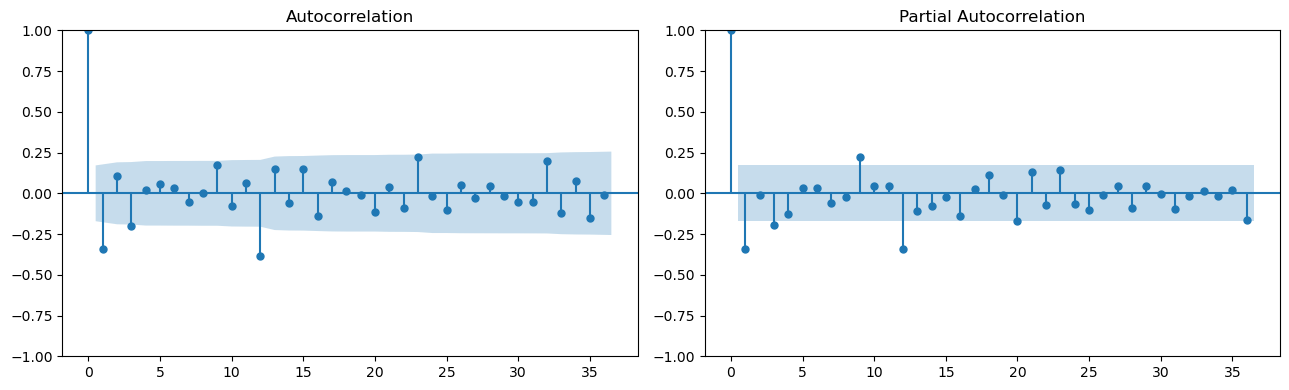

De xuat tu doc ACF/PACF: p=1, q=1, P=1, Q=1


In [5]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

chuoi_da_dung = y_log.diff(1).diff(12).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(chuoi_da_dung, lags=36, ax=axes[0])
plot_pacf(chuoi_da_dung, lags=36, ax=axes[1])
plt.tight_layout()
plt.show()
# Doc ACF: so lag co dinh truoc khi cat -> goi y q (va Q o lag boi cua 12)
# Doc PACF: so lag co dinh truoc khi cat -> goi y p (va P o lag boi cua 12)
# Voi AirPassengers, ACF/PACF thuong goi y bac thap: p=1, q=1, P=1, Q=1
p_de_xuat, q_de_xuat = 1, 1
P_de_xuat, Q_de_xuat = 1, 1
print(f"De xuat tu doc ACF/PACF: p={p_de_xuat}, q={q_de_xuat}, P={P_de_xuat}, Q={Q_de_xuat}")


## 6. Chia theo thoi gian: 120 thang train, 24 thang test

In [6]:
y_train, y_test = y.iloc[:120], y.iloc[120:]
y_log_train, y_log_test = y_log.iloc[:120], y_log.iloc[120:]
print(f"Train: {y_train.index[0]} -> {y_train.index[-1]} ({len(y_train)} thang)")
print(f"Test:  {y_test.index[0]} -> {y_test.index[-1]} ({len(y_test)} thang)")


Train: 1949-01-01 00:00:00 -> 1958-12-01 00:00:00 (120 thang)
Test:  1959-01-01 00:00:00 -> 1960-12-01 00:00:00 (24 thang)


## 7. Hai baseline bat buoc

In [7]:
from sklearn.metrics import mean_absolute_percentage_error

du_bao_naive = pd.Series(y_train.iloc[-1], index=y_test.index)
mape_naive = mean_absolute_percentage_error(y_test, du_bao_naive) * 100

du_bao_seasonal_naive = pd.Series(y_train.iloc[-12:].values, index=y_test.index[:12])
if len(y_test) > 12:
    du_bao_seasonal_naive = pd.concat([
        du_bao_seasonal_naive,
        pd.Series(y_train.iloc[-12:].values[:len(y_test) - 12], index=y_test.index[12:])
    ])
mape_seasonal_naive = mean_absolute_percentage_error(y_test, du_bao_seasonal_naive) * 100

print(f"Naive (thang nay = thang truoc): MAPE = {mape_naive:.2f}%")
print(f"Seasonal naive (thang nay = thang nay nam ngoai): MAPE = {mape_seasonal_naive:.2f}%")
print("Seasonal naive thuong rat manh voi chuoi mua vu ro ret - SARIMA phai thang no moi co gia tri")


Naive (thang nay = thang truoc): MAPE = 23.58%
Seasonal naive (thang nay = thang nay nam ngoai): MAPE = 15.52%
Seasonal naive thuong rat manh voi chuoi mua vu ro ret - SARIMA phai thang no moi co gia tri


## 8. SARIMA thu cong theo ACF/PACF

In [8]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model_thu_cong = SARIMAX(y_log_train, order=(p_de_xuat, d_de_xuat, q_de_xuat),
                          seasonal_order=(P_de_xuat, D_de_xuat, Q_de_xuat, 12),
                          enforce_stationarity=False, enforce_invertibility=False)
fit_thu_cong = model_thu_cong.fit(disp=False)
print(fit_thu_cong.summary())


                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                  120
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 171.311
Date:                            Mon, 05 Oct 2026   AIC                           -332.622
Time:                                    15:49:53   BIC                           -319.959
Sample:                                01-01-1949   HQIC                          -327.509
                                     - 12-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0501      0.255      0.196      0.844      -0.450       0.550
ma.L1         -0.4638      0.235   

## 9. Do tu dong: quet luoi (p,d,q)(P,D,Q,12) theo AIC

In [9]:
import itertools

luoi_pdq = list(itertools.product(range(2), [d_de_xuat], range(2)))
luoi_PDQ = list(itertools.product(range(2), [D_de_xuat], range(2)))

ket_qua_grid = []
for order in luoi_pdq:
    for seasonal_order in luoi_PDQ:
        try:
            m = SARIMAX(y_log_train, order=order, seasonal_order=seasonal_order + (12,),
                        enforce_stationarity=False, enforce_invertibility=False)
            f = m.fit(disp=False)
            ket_qua_grid.append({"order": order, "seasonal_order": seasonal_order, "aic": f.aic})
        except Exception:
            continue

bang_grid = pd.DataFrame(ket_qua_grid).sort_values("aic").reset_index(drop=True)
print(bang_grid.head(10))

bac_tot_nhat = bang_grid.iloc[0]
print(f"\nBac tot nhat theo AIC: order={bac_tot_nhat['order']}, seasonal_order={bac_tot_nhat['seasonal_order']}")
print(f"So sanh voi bac chon thu cong: order=({p_de_xuat},{d_de_xuat},{q_de_xuat}), "
      f"seasonal_order=({P_de_xuat},{D_de_xuat},{Q_de_xuat})")


c:\Users\ADMIN\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\ADMIN\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


       order seasonal_order         aic
0  (1, 1, 0)      (0, 1, 0) -359.977320
1  (0, 1, 1)      (0, 1, 0) -356.202103
2  (1, 1, 1)      (0, 1, 0) -354.635215
3  (0, 1, 0)      (0, 1, 0) -349.816165
4  (1, 1, 0)      (0, 1, 1) -344.392615
5  (0, 1, 1)      (1, 1, 0) -343.451896
6  (0, 1, 1)      (0, 1, 1) -340.692656
7  (1, 1, 0)      (1, 1, 0) -339.651767
8  (1, 1, 1)      (0, 1, 1) -339.171798
9  (1, 1, 1)      (1, 1, 0) -337.874299

Bac tot nhat theo AIC: order=(1, 1, 0), seasonal_order=(0, 1, 0)
So sanh voi bac chon thu cong: order=(1,1,1), seasonal_order=(1,1,1)


In [10]:
model_tu_dong = SARIMAX(y_log_train, order=bac_tot_nhat["order"],
                         seasonal_order=bac_tot_nhat["seasonal_order"] + (12,),
                         enforce_stationarity=False, enforce_invertibility=False)
fit_tu_dong = model_tu_dong.fit(disp=False)

print(f"AIC thu cong: {fit_thu_cong.aic:.2f}")
print(f"AIC tu dong (tim bang grid search): {fit_tu_dong.aic:.2f}")
# Chon model co AIC thap hon de dung cho cac buoc du bao phia sau
fit = fit_tu_dong if fit_tu_dong.aic < fit_thu_cong.aic else fit_thu_cong
print(f"\n=> Dung model {'TU DONG' if fit is fit_tu_dong else 'THU CONG'} cho cac buoc tiep theo")


AIC thu cong: -332.62
AIC tu dong (tim bang grid search): -359.98

=> Dung model TU DONG cho cac buoc tiep theo


## 10. Ljung-Box va bieu do chan doan phan du

      lb_stat  lb_pvalue
12  29.522520   0.003293
24  29.769199   0.192519

Phan du la nhieu trang: KHONG - can xem lai bac model


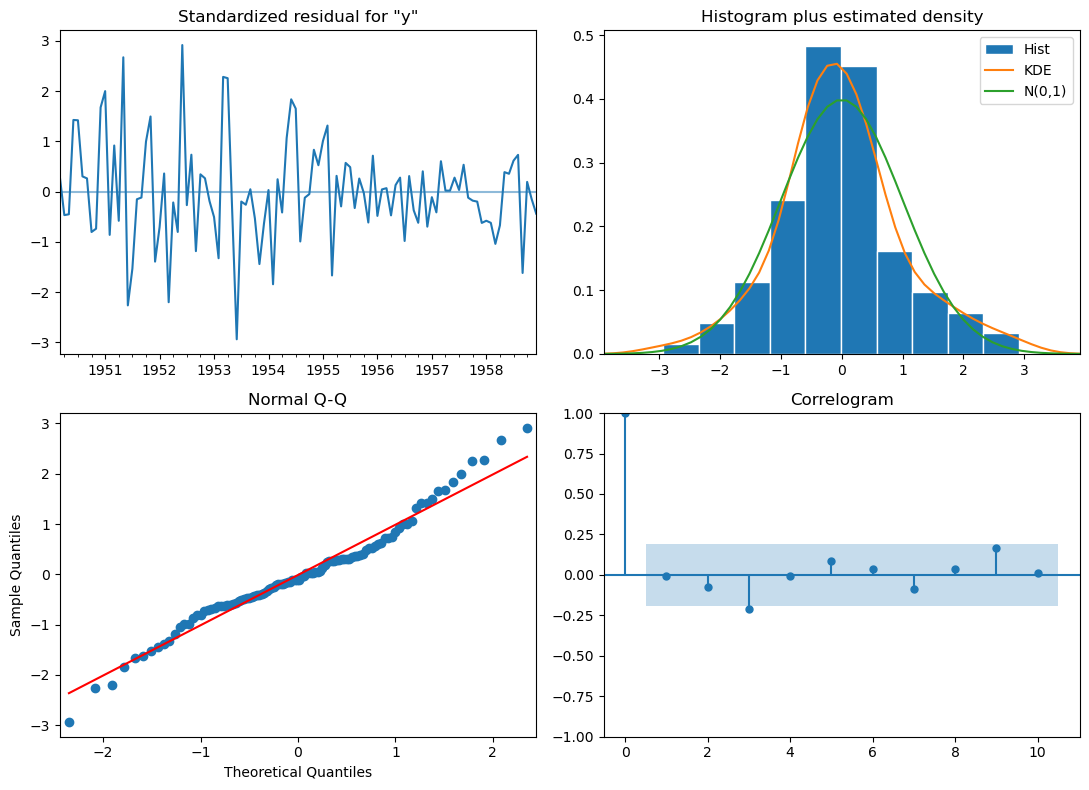

In [11]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb = acorr_ljungbox(fit.resid, lags=[12, 24], return_df=True)
print(lb)
# p-value > 0.05 o moi lag -> phan du la NHIEU TRANG -> model da bat het cau truc
# p-value < 0.05 -> con mau hinh chua bat duoc, can xem lai (p,d,q)(P,D,Q)
dat_nhieu_trang = (lb["lb_pvalue"] > 0.05).all()
print(f"\nPhan du la nhieu trang: {'CO' if dat_nhieu_trang else 'KHONG - can xem lai bac model'}")

fit.plot_diagnostics(figsize=(11, 8))
plt.tight_layout()
plt.show()


## 11. Du bao 24 thang + khoang tin cay, ve chong len thuc te

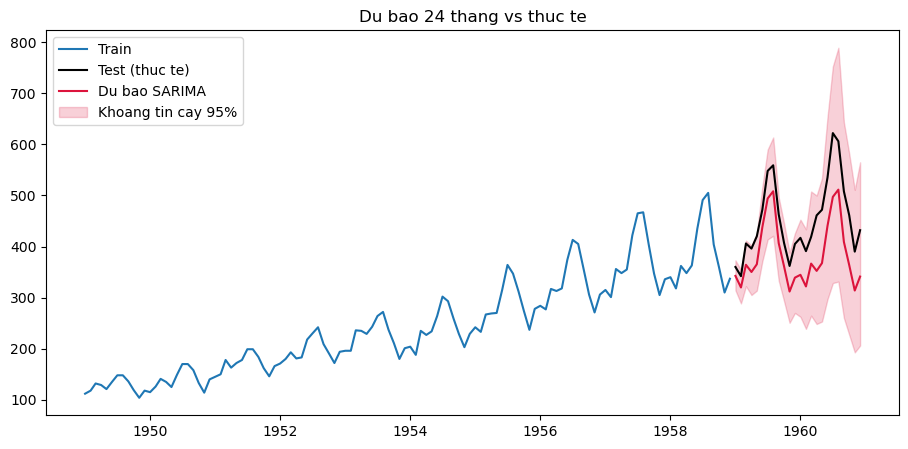

In [12]:
ket_qua_du_bao = fit.get_forecast(steps=24)
du_bao = np.exp(ket_qua_du_bao.predicted_mean)              # doi nguoc tu log
khoang_tin_cay = np.exp(ket_qua_du_bao.conf_int(alpha=0.05))  # khoang 95%
khoang_tin_cay.index = y_test.index
du_bao.index = y_test.index

plt.figure(figsize=(11, 5))
plt.plot(y_train, label="Train")
plt.plot(y_test, label="Test (thuc te)", color="black")
plt.plot(du_bao, label="Du bao SARIMA", color="crimson")
plt.fill_between(khoang_tin_cay.index, khoang_tin_cay.iloc[:, 0], khoang_tin_cay.iloc[:, 1],
                  color="crimson", alpha=0.2, label="Khoang tin cay 95%")
plt.title("Du bao 24 thang vs thuc te")
plt.legend()
plt.show()


## 12. MAPE tren tap test, so voi 2 baseline

In [13]:
mape_sarima = mean_absolute_percentage_error(y_test, du_bao) * 100
print(f"Naive:           MAPE = {mape_naive:.2f}%")
print(f"Seasonal naive:  MAPE = {mape_seasonal_naive:.2f}%")
print(f"SARIMA:          MAPE = {mape_sarima:.2f}%")

if mape_sarima < mape_seasonal_naive:
    print("\n=> SARIMA THANG seasonal naive -> mo hinh co gia tri that su")
else:
    print("\n=> SARIMA KHONG thang seasonal naive -> can xem lai bac model hoac")
    print("   ket luan trung thuc rang baseline don gian da du dung cho chuoi nay")


Naive:           MAPE = 23.58%
Seasonal naive:  MAPE = 15.52%
SARIMA:          MAPE = 14.73%

=> SARIMA THANG seasonal naive -> mo hinh co gia tri that su


## 13. Ti le phu cua khoang du bao 95%

In [14]:
trong_khoang = (y_test >= khoang_tin_cay.iloc[:, 0]) & (y_test <= khoang_tin_cay.iloc[:, 1])
ty_le_phu = trong_khoang.mean() * 100
print(f"Ti le gia tri that roi trong khoang tin cay 95%: {ty_le_phu:.1f}%")
print("Ly tuong gan 95%. Neu thap hon nhieu (vi du 60%), khoang tin cay qua hep,")
print("khong phan anh dung do bat dinh thuc te, khong nen dung de lap ke hoach.")


Ti le gia tri that roi trong khoang tin cay 95%: 100.0%
Ly tuong gan 95%. Neu thap hon nhieu (vi du 60%), khoang tin cay qua hep,
khong phan anh dung do bat dinh thuc te, khong nen dung de lap ke hoach.


## Han che

ARIMA/SARIMA chi dung chinh lich su cua chuoi de du bao, khong dua vao duoc cac
bien ngoai sinh (khuyen mai, ngay le, thoi tiet...). Khi can ket hop nhieu bien
ngoai, nen dung SARIMAX (them bien ngoai sinh) hoac chuyen sang ML + lag features
(XGBoost, xem TT-31) - danh doi lai la mat kha nang ngoai suy trend va khoang tin
cay tu nhien ma ARIMA co san.

## Luu san pham nop (model, hinh, requirements, README)

In [15]:
import os
import pickle

os.makedirs("models", exist_ok=True)
os.makedirs("reports", exist_ok=True)

with open("models/sarima_fit.pkl", "wb") as f:
    pickle.dump(fit, f)

fig, axes = plt.subplots(2, 1, figsize=(10, 8))
for ax, mo_hinh in zip(axes, ["additive", "multiplicative"]):
    phan_ra = seasonal_decompose(y, model=mo_hinh, period=12)
    ax.plot(phan_ra.resid)
    ax.set_title(f"Phan du - mo hinh {mo_hinh}")
plt.tight_layout()
plt.savefig("reports/decompose.png", dpi=150, bbox_inches="tight"); plt.close()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(chuoi_da_dung, lags=36, ax=axes[0])
plot_pacf(chuoi_da_dung, lags=36, ax=axes[1])
plt.tight_layout()
plt.savefig("reports/acf_pacf.png", dpi=150, bbox_inches="tight"); plt.close()

fig = fit.plot_diagnostics(figsize=(11, 8))
plt.tight_layout()
plt.savefig("reports/residual_diagnostics.png", dpi=150, bbox_inches="tight"); plt.close()

plt.figure(figsize=(11, 5))
plt.plot(y_train, label="Train")
plt.plot(y_test, label="Test (thuc te)", color="black")
plt.plot(du_bao, label="Du bao SARIMA", color="crimson")
plt.fill_between(khoang_tin_cay.index, khoang_tin_cay.iloc[:, 0], khoang_tin_cay.iloc[:, 1],
                  color="crimson", alpha=0.2, label="Khoang tin cay 95%")
plt.title("Du bao 24 thang vs thuc te")
plt.legend()
plt.savefig("reports/du_bao_khoang.png", dpi=150, bbox_inches="tight"); plt.close()

with open("requirements.txt", "w") as f:
    f.write("statsmodels\npandas\nnumpy\nmatplotlib\nscikit-learn\n")

readme_content = f"""# TT-30 - ARIMA/SARIMA: Du bao luong khach hang theo thang

## Huong dan chay
1. Cai thu vien: `pip install -r requirements.txt`
2. Can mang o lan chay dau de statsmodels tai du lieu AirPassengers
3. Restart Kernel roi Run All
4. Ket qua duoc luu vao models/ va reports/ khi chay den cell cuoi

## Cac buoc da thuc hien va nhan xet

1. Chuoi goc co trend tang va mua vu chu ky 12 thang, bien do phinh dan theo trend.
2. seasonal_decompose xac nhan mo hinh multiplicative hop hon additive (phan du phang hon).
3. Lay log(y) de bien thanh cong tinh, bien do mua vu da on dinh qua cac nam.
4. Bang ADF cho 4 phien ban chuoi:
{bang_adf.to_string(index=False)}
   De xuat d={d_de_xuat}, D={D_de_xuat}.
5. ACF/PACF cua chuoi da dung (xem reports/acf_pacf.png) goi y p={p_de_xuat}, q={q_de_xuat},
   P={P_de_xuat}, Q={Q_de_xuat}.
6. Chia train 120 thang, test 24 thang.
7. Baseline: Naive MAPE={mape_naive:.2f}%, Seasonal naive MAPE={mape_seasonal_naive:.2f}%.
8. SARIMA thu cong order=({p_de_xuat},{d_de_xuat},{q_de_xuat}) seasonal_order=({P_de_xuat},{D_de_xuat},{Q_de_xuat},12),
   AIC={fit_thu_cong.aic:.2f}.
9. Do tu dong bang grid search theo AIC: bac tot nhat order={bac_tot_nhat['order']},
   seasonal_order={bac_tot_nhat['seasonal_order']}, AIC={fit_tu_dong.aic:.2f}.
   Dung model {'tu dong' if fit is fit_tu_dong else 'thu cong'} cho cac buoc sau vi AIC thap hon.
10. Ljung-Box tai lag 12, 24 (xem reports/residual_diagnostics.png):
{lb.to_string()}
    Phan du la nhieu trang: {"CO" if dat_nhieu_trang else "KHONG"}.
11. Du bao 24 thang + khoang tin cay 95% (xem reports/du_bao_khoang.png).
12. MAPE tren test: SARIMA={mape_sarima:.2f}%, so voi Naive={mape_naive:.2f}%,
    Seasonal naive={mape_seasonal_naive:.2f}%.
    SARIMA {"THANG" if mape_sarima < mape_seasonal_naive else "KHONG thang"} seasonal naive.
13. Ti le phu khoang tin cay 95%: {ty_le_phu:.1f}% (ly tuong gan 95%).

## Han che
ARIMA/SARIMA chi dung lich su cua chinh chuoi, khong dua vao bien ngoai sinh.
Can bien ngoai (khuyen mai, le tet, thoi tiet) thi dung SARIMAX hoac ML + lag features.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_content)

print("Da luu: models/sarima_fit.pkl, reports/*.png, requirements.txt, README.md")


Da luu: models/sarima_fit.pkl, reports/*.png, requirements.txt, README.md
